In [ ]:
import numpy as np
import pandas as pd
import sklearn
import kagglehub
import glob
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.ensemble import ExtraTreesClassifier

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
path = kagglehub.dataset_download("zahrashahzahi/stock-market-dataset")

Using Colab cache for faster access to the 'stock-market-dataset' dataset.


In [ ]:
csv_file = glob.glob(f'{path}/*.csv')[0]

In [ ]:
df = pd.read_csv(csv_file)
df.head()

,Index,Date,Open,High,Low,Close,Adj Close,Volume
0,NYA,12/31/1965,528.690002,528.690002,528.690002,528.690002,528.690002,0.0
1,NYA,1/3/1966,527.210022,527.210022,527.210022,527.210022,527.210022,0.0
2,NYA,1/4/1966,527.840027,527.840027,527.840027,527.840027,527.840027,0.0
3,NYA,1/5/1966,531.119995,531.119995,531.119995,531.119995,531.119995,0.0
4,NYA,1/6/1966,532.070007,532.070007,532.070007,532.070007,532.070007,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112457 entries, 0 to 112456
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Index      112457 non-null  object 
 1   Date       112457 non-null  object 
 2   Open       110253 non-null  float64
 3   High       110252 non-null  float64
 4   Low        110251 non-null  float64
 5   Close      110250 non-null  float64
 6   Adj Close  110244 non-null  float64
 7   Volume     110253 non-null  float64
dtypes: float64(6), object(2)
memory usage: 6.9+ MB


In [ ]:
df['Volume'][10000:10010]

,Volume
10000,2.424720e+09
10001,1.973020e+09
10002,2.022220e+09
10003,1.976270e+09
10004,2.106980e+09
10005,2.176120e+09
10006,2.097520e+09
10007,2.097490e+09
10008,2.341420e+09
10009,2.546780e+09


In [ ]:
df_filled = df.ffill()

In [ ]:
df_filled.isnull().sum()

,0
Index,0
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0


In [ ]:
df_filled['Daily_range'] = df_filled['High'] - df_filled['Low']
df_filled['Daily_range'].head()

,Daily_range
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0


In [ ]:
print(df_filled['Date'].dtype)
df_filled['Date'] = pd.to_datetime(df_filled['Date'])
print(df_filled['Date'].dtype)

object
datetime64[ns]


In [ ]:
df_filled = df_filled.sort_values('Date').reset_index(drop = True)

In [ ]:
plt.figure(figsize = (12, 6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

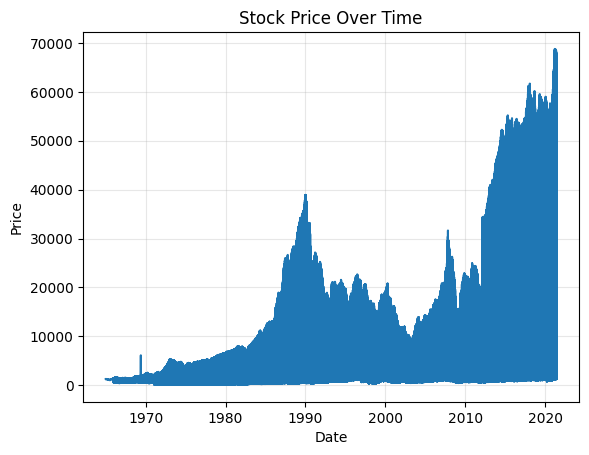

In [ ]:
plt.plot(df_filled['Date'], df_filled['Adj Close'])
plt.title('Stock Price Over Time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.grid(True, alpha=0.3)

plt.show()

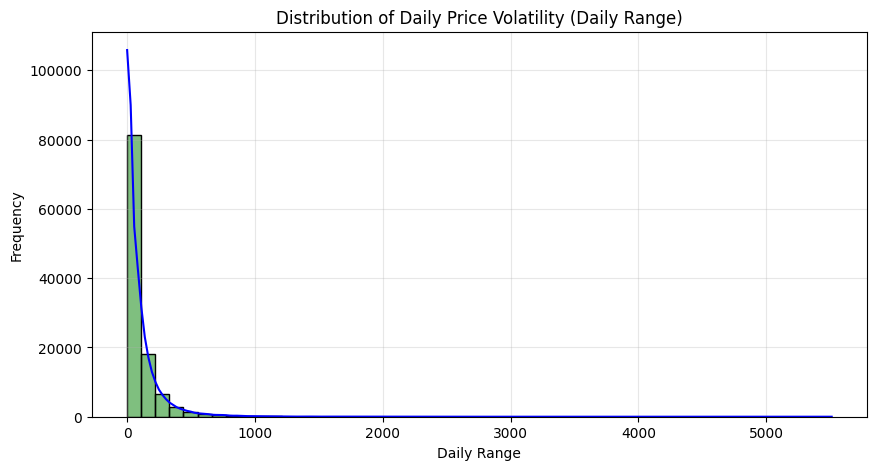

In [ ]:
plt.figure(figsize = (10, 5))
ax = sns.histplot(df_filled['Daily_range'], bins = 50, kde = True, color = 'green')
ax.lines[0].set_color('blue')

plt.title('Distribution of Daily Price Volatility (Daily Range)')
plt.xlabel('Daily Range')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()


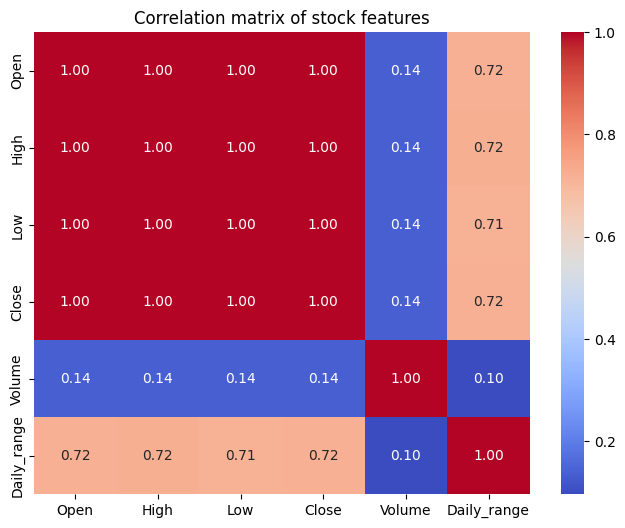

In [ ]:
plt.figure(figsize = (8, 6))
correlation_matrix = df_filled[['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_range']].corr()

sns.heatmap(correlation_matrix, annot = True, cmap = 'coolwarm', fmt = '.2f')

plt.title("Correlation matrix of stock features")
plt.show()

In [ ]:
df_new_era = df_filled.loc['2005-01-01':].copy()

In [ ]:
df_new_era['Target_price'] = df_new_era['Adj Close'].shift(-1)
df_new_era['Target'] = (df_new_era['Target_price'] > df_new_era['Adj Close']).astype(int)

df_new_era = df_new_era.dropna(subset = ['Target_price']).copy()

In [ ]:
X_new_era = df_new_era[['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_range']]
y_new_era = df_new_era['Target']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_new_era, y_new_era, test_size = 0.2, random_state = 42, shuffle = False)


In [ ]:
print("Target distribution in test set:")
print(y_test.value_counts(normalize=True))

Target distribution in test set:
Target
0    0.50119
1    0.49881
Name: proportion, dtype: float64


In [ ]:
clf = RandomForestClassifier(n_estimators = 100, max_depth = 5, random_state = 42)
clf.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, random_state=42)

In [ ]:
preds = clf.predict(X_test)
print(preds)

[0 0 1 ... 1 0 0]


In [ ]:
print("Out-of-Sample Accuracy:", accuracy_score(y_test, preds))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, preds))
print("\nDetailed Breakdown:\n", classification_report(y_test, preds))

Out-of-Sample Accuracy: 0.6847743750676334

Confusion Matrix:
 [[8888  375]
 [5451 3768]]

Detailed Breakdown:
               precision    recall  f1-score   support

           0       0.62      0.96      0.75      9263
           1       0.91      0.41      0.56      9219

    accuracy                           0.68     18482
   macro avg       0.76      0.68      0.66     18482
weighted avg       0.76      0.68      0.66     18482



In [ ]:
xgb_model = xgb.XGBClassifier(n_estimators = 100, max_depth = 5, random_state = 42)
xgb_model.fit(X_new_era, y_new_era)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
preds_xgb = xgb_model.predict(X_test)
print(preds_xgb)

[1 1 1 ... 1 0 1]


In [ ]:
print("Out-of-Sample Accuracy:", accuracy_score(y_test, preds_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, preds_xgb))
print("\nDetailed Breakdown:\n", classification_report(y_test, preds_xgb))

Out-of-Sample Accuracy: 0.7587923384915053

Confusion Matrix:
 [[7710 1553]
 [2905 6314]]

Detailed Breakdown:
               precision    recall  f1-score   support

           0       0.73      0.83      0.78      9263
           1       0.80      0.68      0.74      9219

    accuracy                           0.76     18482
   macro avg       0.76      0.76      0.76     18482
weighted avg       0.76      0.76      0.76     18482



In [ ]:
lr_model = make_pipeline(StandardScaler(), LogisticRegression(random_state = 42, max_iter = 1000))
lr_model.fit(X_new_era, y_new_era)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [ ]:
preds_lr = lr_model.predict(X_test)
print(preds_lr)

[1 1 1 ... 1 0 0]


In [ ]:
print("Out-of-Sample Accuracy:", accuracy_score(y_test, preds_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, preds_xgb))
print("\nDetailed Breakdown:\n", classification_report(y_test, preds_xgb))

Out-of-Sample Accuracy: 0.7587923384915053

Confusion Matrix:
 [[7710 1553]
 [2905 6314]]

Detailed Breakdown:
               precision    recall  f1-score   support

           0       0.73      0.83      0.78      9263
           1       0.80      0.68      0.74      9219

    accuracy                           0.76     18482
   macro avg       0.76      0.76      0.76     18482
weighted avg       0.76      0.76      0.76     18482



In [ ]:
et_model = ExtraTreesClassifier(n_estimators = 100, max_depth = 5, random_state = 42)
et_model.fit(X_new_era, y_new_era)

ExtraTreesClassifier(max_depth=5, random_state=42)

In [ ]:
preds_et = et_model.predict(X_test)
print(preds_et)

[0 0 1 ... 1 0 0]


In [ ]:
print("Out-of-Sample Accuracy:", accuracy_score(y_test, preds_et))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, preds_et))
print("\nDetailed Breakdown:\n", classification_report(y_test, preds_et))

Out-of-Sample Accuracy: 0.6863975760199112

Confusion Matrix:
 [[8877  386]
 [5410 3809]]

Detailed Breakdown:
               precision    recall  f1-score   support

           0       0.62      0.96      0.75      9263
           1       0.91      0.41      0.57      9219

    accuracy                           0.69     18482
   macro avg       0.76      0.69      0.66     18482
weighted avg       0.76      0.69      0.66     18482

